# SSAMBA self-supervised pretraining

The masked spectrogram patch modelling objective SSAMBA-tiny is pretrained with in arms B and C of the pretraining comparison
(`src/encoder_pipeline/model_trainer/ssamba.py`, `SSAMBAModel`; hparams from
`configs/pretraining_comparison/B_ssl_source/01_pretrain_ssamba_tiny_ssl_source.yaml`, same as C's):

1. a 3 s log-mel spectrogram (256 × 563) is cut into 16 × 35 = 560 patches of 16 × 16
2. 400 of them (71 %) are masked in square clusters 3–5 patches wide (`gen_maskid_patch`, called below, so the mask is
   one the pipeline would actually draw) and replaced by a learned [MASK] embedding
3. the bidirectional Mamba (Vim) encoder, 24 blocks at 192-d, encodes the whole sequence
4. at each masked position two MLP heads predict the patch: InfoNCE picks the true patch among the clip's 400 masked
   patches, MSE reconstructs it; loss = InfoNCE + 10 × MSE

The clip is a real SRKW call from the Lime Kiln fine-tune set (the Strait of Georgia hydrophones are band-limited, so
their clips leave the top of the mel range empty). The figure is just the clip and its masked version. Change `CLIP_RANK` / `SEED` for another clip / mask; set
`PATCH_GRID = True` to draw the 16 × 16 patch grid over both.

In [1]:
from types import SimpleNamespace

import h5py
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Rectangle

from encoder_pipeline.model_trainer.ssamba import SSAMBA_VARIANTS, SSAMBAModel

HDF5 = "/home/noah/HALLO_encoder_collection/data/preprocessor/c09f6de95daef542_20261024_195217.h5"  # Lime Kiln fine-tune set (full band; the SoG hydrophones are band-limited)
CLIP_LABEL = "SRKW"
CLIP_RANK = 0  # 0 = the SRKW clip with the strongest call contrast; bump to browse others
SEED = 3  # which random mask is drawn
PATCH_GRID = False  # draw the patch grid lines
# configs/pretraining_comparison/B_ssl_source/01_pretrain_ssamba_tiny_ssl_source.yaml (= C's)
F_DIM, T_DIM, FSHAPE, TSHAPE, MASK_PATCH, VARIANT, MSE_WEIGHT = 256, 563, 16, 16, 400, "ssamba_tiny", 10.0
P_F, P_T = F_DIM // FSHAPE, T_DIM // TSHAPE  # 16 x 35 = 560 patches; the last 3 frames fall outside the patch grid
EMBED_DIM, DEPTH = SSAMBA_VARIANTS[VARIANT]["embed_dim"], SSAMBA_VARIANTS[VARIANT]["depth"]
SECONDS = T_DIM * 128 / 24000  # hop 128 at 24 kHz

INK, MUTED = "#1f1f1f", "#5f5f5f"
MASK = "#c9ccd1"
C_ENC, C_NCE, C_MSE = "#2a78d6", "#1baf7a", "#eb6834"  # dataviz reference palette slots 1, 3, 2

with h5py.File(HDF5, "r") as h5:
    rows = np.flatnonzero(h5["Labels"].asstr()[:] == CLIP_LABEL)[:400]
    specs = h5["spec"][rows]  # (n, 256 mel, 563 frames)
contrast = [np.percentile(s[40:200], 99.5) - np.median(s[40:200]) for s in specs]  # call energy over the noise floor
spec = specs[np.argsort(contrast)[::-1][CLIP_RANK]]
spec = (spec - spec.mean()) / (spec.std() + 1e-5)  # SSAMBABackbone.normalize

np.random.seed(SEED)
masker = SimpleNamespace(cluster=True, mask_patch=MASK_PATCH,
                         backbone=SimpleNamespace(num_patches=P_F * P_T, p_t_dim=P_T))
mask_index = SSAMBAModel.gen_maskid_patch(masker)  # the pipeline's own cluster masking
masked = np.zeros(P_F * P_T, bool)
masked[mask_index] = True
masked = masked.reshape(P_F, P_T)  # patch id = freq row * P_T + time col (Conv2d / Unfold order)


In [2]:
def show_spec(ax):
    ax.imshow(spec, origin="lower", aspect="auto", cmap="magma", extent=(0, T_DIM, 0, F_DIM), vmin=-1.5, vmax=3.5)
    if PATCH_GRID:
        for f in range(P_F + 1):
            ax.axhline(f * FSHAPE, color="white", lw=0.35, alpha=0.55)
        for t in range(P_T + 1):
            ax.axvline(t * TSHAPE, color="white", lw=0.35, alpha=0.55)
    ax.set_xlim(0, T_DIM)
    ax.set_ylim(0, F_DIM)
    ax.set_axis_off()

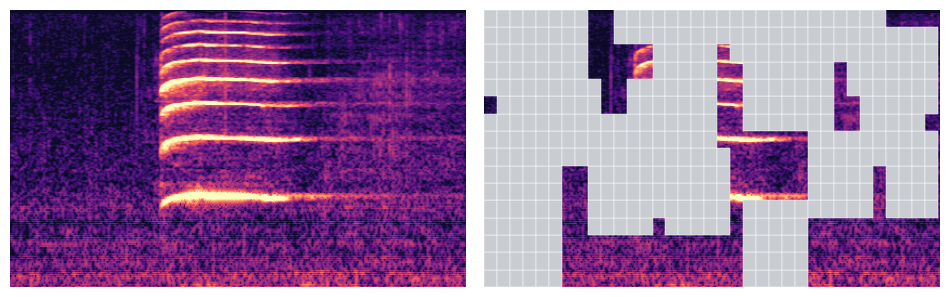

In [3]:
fig, (ax_in, ax_mask) = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"wspace": 0.04})
show_spec(ax_in)
show_spec(ax_mask)
for f, t in zip(*np.nonzero(masked)):
    ax_mask.add_patch(Rectangle((t * TSHAPE, f * FSHAPE), TSHAPE, FSHAPE, fc=MASK, ec="white", lw=0.35))
plt.show()

In [4]:
# optional: save for the paper
# fig.savefig("ssamba_pretraining.png", dpi=300, bbox_inches="tight"); fig.savefig("ssamba_pretraining.pdf", bbox_inches="tight")